# The leakage-safe protocol per case, with gates

**Question:** When a feature leaks the outcome into development, which validation tests see it and how often, and how much do the declared splits of C01, C02 and C03 protect the fits of the product against it?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 02 to 05 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state the leakage-safe protocol of Contraste, the six rules it enforces and the split each of the three credit-scoring cases declares;
- check on the committed artifacts of C01, C02 and C03 what the protocol's gates guarantee, and see the engine refuse a vintage whose target is not observable yet;
- measure what a leak looks like to the engine's tests, with a planted leak of known size, by simulation and against the exact truth of the generator;
- say exactly what the claim states and what it does not: enforcement of known rules by gates, not a new method.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
import re
from datetime import date

from riskvalidation.generators.scores import BinormalScores
from riskvalidation.stress.paths import check_vintage
from riskvalidation.validation.discrimination import disc_auc, disc_auc_vs_initial
from riskvalidation.validation.stability import bin_counts, quantile_edges, stability_csi

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The notebook reads the evidence that the claim lists, and nothing else:

- the requirements and the gates: `docs/design/features/c01-retail-pd/requirements.md` (the EARS requirements CT-101 to CT-103, each with the test that fails when it is violated). The gates themselves are in `tests/test_leakage.py`; running them needs the pipeline libraries, which the notebook environment does not carry;
- the declared split of each case, as committed: `data/derived/C01/models-taiwan.json` and `holdout.json`, `data/derived/C02/h1.json` to `h5.json` and `pooled.json`, `data/derived/C03/fy2015-17.json`, `fy2018-20.json` and `models-sba-7a.json`;
- the planted leak of case C22: `data/derived/C22/leakage.json`, synthetic with a known truth (no third-party licence; generated by the engine from a seed).

The real data behind C01, C02 and C03 are the UCI Taiwan credit-card file (Yeh, 2009; CC BY 4.0; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), the UCI Polish companies file (Tomczak, 2016; CC BY 4.0; https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data) and the U.S. SBA 7(a) loan file (U.S. Government Works; https://data.sba.gov/dataset/7a-504-foia); all three are `mirror-allowed`. The next cell loads the files and prints the three requirements with their gates and the limit that each case states.

In [2]:
# Load the committed evidence of the claim and print its gates and the limits the artifacts state
ROOT = Path("../../..").resolve()
names = ["C01/models-taiwan", "C01/holdout", "C22/leakage", "C03/models-sba-7a", "C03/fy2015-17", "C03/fy2018-20"]
names += [f"C02/{h}" for h in ("h1", "h2", "h3", "h4", "h5", "pooled")]
docs = {n: json.loads((ROOT / "data" / "derived" / f"{n}.json").read_text(encoding="utf-8")) for n in names}
c01, c01_holdout, c22 = docs["C01/models-taiwan"], docs["C01/holdout"], docs["C22/leakage"]
c02 = {h: docs[f"C02/{h}"] for h in ("h1", "h2", "h3", "h4", "h5", "pooled")}
c03_models = docs["C03/models-sba-7a"]
c03 = {n: docs[f"C03/{n}"] for n in ("fy2015-17", "fy2018-20")}
feature = ROOT / "docs" / "design" / "features" / "c01-retail-pd"
requirements = (feature / "requirements.md").read_text(encoding="utf-8")
policy = rv.default_policy()
LANG = "en"
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
for line in requirements.splitlines():
    if re.match(r"\| CT-10[123] ", line):
        cells_ = [c.strip() for c in line.strip().strip("|").split("|")]
        print(cells_[0], cells_[2])
f_oot = next(f for f in c01_holdout["findings"] if f["id"] == "F-OOT")
f_data = next(f for f in c03["fy2015-17"]["findings"] if f["id"] == "F-DATA")
print("C01", f_oot["id"], "|", f_oot["title"][LANG])
print("C02 out_of_time_claim =", c02["h3"]["outputs"]["split"]["out_of_time_claim"])
print("C03", f_data["id"], "|", f_data["title"][LANG])
baked = c01_holdout["provenance"]["riskvalidation_version"]
print("baked by riskvalidation", baked, "| installed", rv.__version__)

CT-101 `tests/test_leakage.py::test_fitted_transforms_train_only`
CT-102 `tests/test_leakage.py::test_calibration_slice_disjoint`
CT-103 `tests/test_leakage.py::test_outside_information_perturbation_invariance`
C01 F-OOT | No out-of-time validation is possible: the data is a single snapshot
C02 out_of_time_claim = False
C03 F-DATA | SBA 7(a) small-business loans under a federal guarantee, not a bank's SME book; no delinquency, balance or rating
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: the rules, the requirements and the gates

The research basis of the product (dossier 04, "universal leakage rules") states six rules for every scoring pipeline:

1. every feature is computed from information available at the observation date, and the performance window starts after it;
2. binning, WoE, imputation, scaling and feature selection are fitted on the training slice only;
3. calibration maps are fitted on a separate calibration slice, never on the test slice;
4. nothing is resampled before calibration is measured;
5. for loss given default and credit conversion factors, the training set holds only defaults whose workout or reference window closed before the training cut-off;
6. macro covariates enter with the lag that would have been available in real time.

Rules 1 to 4 apply to the scoring cases (rules 5 and 6 belong to topics 05 and 12). What the product adds is the second half of each rule: a requirement in the EARS form (Mavin et al., 2009, https://doi.org/10.1109/RE.2009.9) that names **the gate that fails when the rule is violated**. The loading cell printed requirements CT-101, CT-102 and CT-103 with their gates: the fit is on the training slice only, the calibration map has its own slice, and every fitted parameter is unchanged when a value outside the training information is perturbed. The gates are in `tests/test_leakage.py` and run the case's own fitting path twice, once on a planted data set and once with the holdout and the calibration inputs changed; a fitted parameter that moves read something it must not have. They need the pipeline libraries, so this notebook cannot run them. It checks, on the committed artifacts, the properties that the gates guarantee, case by case, starting with C01: the cell draws the three slices and the number of cards behind each of the 13 binned variables.

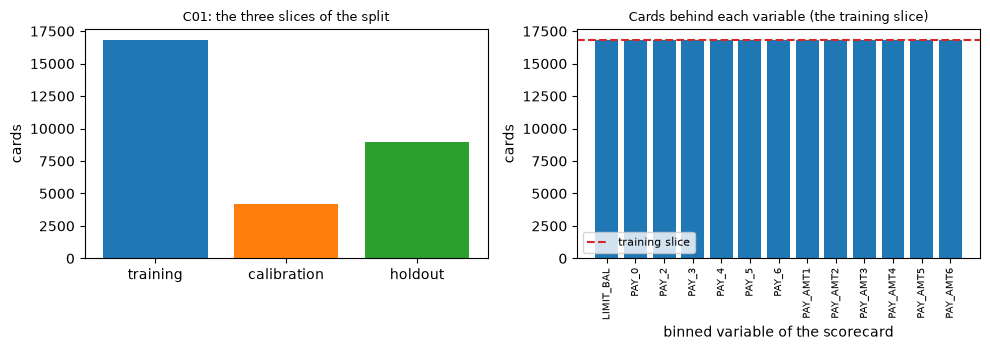

calibration maps and the slice each was fitted on: [('P3-ebm', 'calibration slice'), ('P4-lightgbm', 'calibration slice'), ('P4-xgboost', 'calibration slice')]
distinct totals behind the 13 variables: [16800]


In [3]:
# The three slices of the C01 split, and the number of cards behind each binned variable of the scorecard
split = c01["fit"]["split"]
card = next(m for m in c01["model"] if m["id"] == "P1-scorecard")["details"]
sums = {n: sum(r["count"] for r in card["points_table"] if r["feature"] == n) for n in card["features"]}
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
sizes = [split[k]["n"] for k in ("train", "calibration", "holdout")]
left.bar(["training", "calibration", "holdout"], sizes, color=["tab:blue", "tab:orange", "tab:green"])
left.set_ylabel("cards")
left.set_title("C01: the three slices of the split", fontsize=9)
right.bar(list(sums), list(sums.values()), color="tab:blue")
right.axhline(split["train"]["n"], color="tab:red", linestyle="--", label="training slice")
right.tick_params(axis="x", labelrotation=90, labelsize=7)
right.set_xlabel("binned variable of the scorecard")
right.set_ylabel("cards")
right.set_title("Cards behind each variable (the training slice)", fontsize=9)
right.legend(fontsize=8)
fig.tight_layout()
plt.show()
maps = [(m["id"], m["calibration"]["fitted_on"].replace("calibration slice", "calibration slice"))
        for m in c01["model"] if m["calibration"] is not None]
print("calibration maps and the slice each was fitted on:", maps)
print("distinct totals behind the 13 variables:", sorted(set(sums.values())))

The three slices partition the 30,000 cards of the file into 16,800, 4,200 and 9,000, and the counts behind every one of the 13 binned variables are a single total, 16,800: the binning saw the training slice and nothing else. All three calibration maps (the boosting machine, LightGBM and XGBoost) were fitted on the calibration slice. These are the facts CT-101 and CT-102 guarantee, read from the artifact; the figure shows them but cannot show the counterfactual, that a fit which peeked at the holdout would give different counts.

### Step 2: C02, flags that refuse a claim

The Polish files have no date and no company identifier, so C02's protocol is a locked, stratified holdout within each file, and **it refuses the claims the data cannot support**. Four flags are committed in the split block of every horizon file and of the pooled file: the fit uses the training slice only, the calibration map has its own slice, nothing is resampled before calibration, and no out-of-time claim is made. The cell draws the rows of the three slices of the six files, and prints for each whether the four flags hold and whether the three slices add up to the rows of the file.

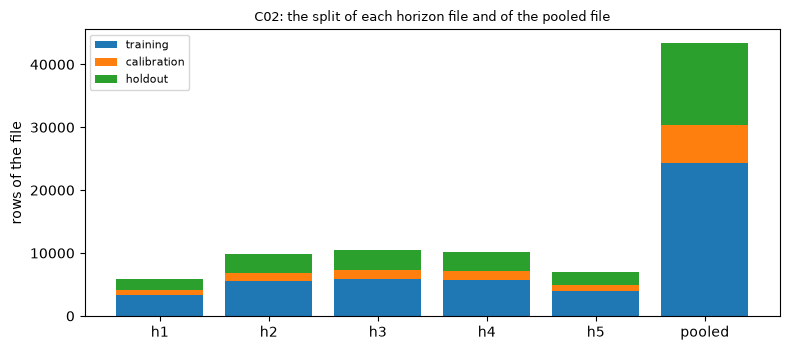

four flags hold, rows partition: h1 True True
four flags hold, rows partition: h2 True True
four flags hold, rows partition: h3 True True
four flags hold, rows partition: h4 True True
four flags hold, rows partition: h5 True True
four flags hold, rows partition: pooled True True


In [4]:
# The rows of the training, calibration and holdout slices of the six C02 files, and their four committed flags
fig, ax = plt.subplots(figsize=(8, 3.6))
bottom = np.zeros(len(c02))
keys = ("train_rows", "calibration_rows", "holdout_rows")
parts = zip(keys, ("tab:blue", "tab:orange", "tab:green"), ["training", "calibration", "holdout"])
for key, color, label in parts:
    values = np.array([doc["outputs"]["split"][key] for doc in c02.values()])
    ax.bar(list(c02), values, bottom=bottom, color=color, label=label)
    bottom += values
ax.set_ylabel("rows of the file")
ax.set_title("C02: the split of each horizon file and of the pooled file", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for name, doc in c02.items():
    s, rows = doc["outputs"]["split"], doc["outputs"]["counts"]["rows"]
    flags = [s["fit_on_training_slice_only"], s["calibration_map_on_separate_slice"]]
    flags += [not s["resampling_before_calibration"], not s["out_of_time_claim"]]
    total = s["train_rows"] + s["calibration_rows"] + s["holdout_rows"]
    print("four flags hold, rows partition:", name, all(flags), total == rows)

For the five horizon files and the pooled file, the four flags hold and the three slices add up to the rows of the file. The bars have the same shape, 56%, 14% and 30% of the rows, since the same stratified split is applied to each. The caveat on the pooled file stays: with no company identifier a company may sit in the training slice of one horizon and in the holdout of another, and the pooled flags cannot say otherwise (notebook 05).

### Step 3: C03, a target read only where it is observable

C03 is the one case with dates, and its protocol is out of time: the training window closes on the 5-year mark of its last approval year, before the test cohort starts, and the target of a vintage is read only at its own 5-year mark (notebook 04). That rule also bounds the data: a vintage can be tested only once its 5-year mark has passed on the date of the file. The engine carries this rule as `check_vintage`, which refuses a vintage whose date postdates the observation date. The cell asks it about the six vintages of the two latest cohorts, finds the last approval year whose mark has passed and asks about the year after it, where the engine must refuse.

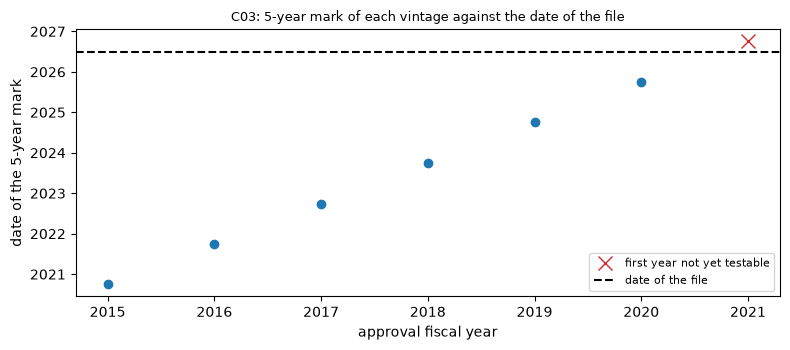

vintages accepted by the engine's rule: 6
last approval year that can be tested, and the engine's refusal of the next: 2020
the engine refuses the mark after the date of the file: 2026-09-30 > 2026-06-30


In [5]:
# The engine's rule on observability: a vintage whose 5-year mark postdates the file cannot be read, so it is refused
as_of = c03_models["fit"]["data_status"]["files_as_of"]
accepted = 0
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, doc in c03.items():
    for v in doc["outputs"]["vintage_summary"]["rows"]:
        check_vintage(v["five_year_mark_date"], as_of)
        accepted += 1
        mark = date.fromisoformat(v["five_year_mark_date"])
        ax.plot(v["fiscal_year"], mark.year + mark.timetuple().tm_yday / 366, "o", color="tab:blue")
last = max(fy for fy in range(1991, 2031) if date(fy + 5, 9, 30) <= date.fromisoformat(as_of))
refused_mark = f"{last + 6}-09-30"
try:
    check_vintage(refused_mark, as_of)
except ValueError:
    refused_mark = f"{refused_mark} > {as_of}"
ax.plot(last + 1, last + 6 + 0.75, "x", color="tab:red", markersize=10, label="first year not yet testable")
ax.axhline(date.fromisoformat(as_of).year + 0.5, color="black", linestyle="--", label="date of the file")
ax.set_xlabel("approval fiscal year")
ax.set_ylabel("date of the 5-year mark")
ax.set_title("C03: 5-year mark of each vintage against the date of the file", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("vintages accepted by the engine's rule:", accepted)
print("last approval year that can be tested, and the engine's refusal of the next:", last)
print("the engine refuses the mark after the date of the file:", refused_mark)

The engine accepts the six vintages, and the figure shows why: the dots, the 5-year marks of FY2015 to FY2020, all lie below the dashed line of the file's date, 2026-06-30. FY2020 is the last approval year that can be tested (its mark is 2025-09-30), and for FY2021, whose mark would be 2026-09-30, the engine refuses it, and the cell prints the mark it refused next to the date of the file. The design stops there instead of reading a target that is not yet observable, so the last cohort cannot end later than FY2020.

### Step 4: what each split cannot claim

A protocol that enforces rules also has to say where they stop. The artifacts state the limits themselves, and the loading cell printed them. C01 is a single snapshot of 2005: finding `F-OOT`, accepted, says no out-of-time validation is possible. C02 sets `out_of_time_claim` to false and labels its cross-file transfer exploratory. C03 is out of time but is the SBA programme, not a bank's SME book (finding `F-DATA`, accepted). The enforcement stops where the data stops, and it says so.

## Comparison

What the research found, and where it stops:

- **The rules are known.** Dossier 04 states the six rules above for credit scoring pipelines, and dossier 06 lists the leakage screens that exist in open toolkits: a label-leaking test, a sample-leaking test, and a resemblance model between development and out-of-time samples.
- **The evaluation is known to matter.** Kozodoi, Lessmann, Alamgir, Moreira-Matias and Papakonstantinou (2025, https://doi.org/10.1016/j.ejor.2025.01.040) propose a framework to train and to **evaluate** credit scoring models under sampling bias, and find that addressing the bias in the evaluation has a larger business impact than in the training. How a model is evaluated is where leaks hide.
- **The practice is not enforced.** Dossier 07 names the single-split evaluation of an open toolkit as the counter-example: one split, no separate calibration slice, no statement of what the data cannot claim. The toolkits give screens to run; none gives a protocol declared per case with a gate that fails when it is broken.

## Evidence

The claim (the list of claims of `docs/design/SDD.md`) is this: **the leakage-safe protocol is declared per case and enforced by gates**. It is enforcement of known rules, not a new method, and it is stated only as far as the evidence goes: the split of each case is declared and recorded in its artifact (steps 1 to 3); the rules are requirements with a named gate; and the protocol states what each split cannot claim (step 4). One more piece of evidence is what a leak looks like to the tests, because a gate on the fitting path protects the fits of the product, while a validator facing someone else's model has only the tests. Case C22 plants a leak of known size: the score is the genuine score plus one feature that **in development carries the outcome**, shifted by the leak size for defaulters, and **at decision time is noise**. The engine's generator `BinormalScores` knows the exact AUC. The cell draws one seeded sample with a leak of 1 and one with no leak (the null) and calls the engine's discrimination tests on both: the AUC of the development sample, the AUC now, and the one-sided test of the AUC against development (Hanley and McNeil, 1982).

In [6]:
# One seeded sample with a leak of 1 and one with none, and the engine's AUC against development on each
samples = {}
for leak in (0.0, 1.0):
    generator = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=leak)
    sample = generator.draw(np.random.default_rng(42))
    kw = dict(policy=policy, model_id="leak")
    auc_dev = disc_auc(sample["development_risk"], sample["development_defaults"], **kw).metric
    auc_now = disc_auc(sample["risk"], sample["defaults"], **kw).metric
    drop = disc_auc_vs_initial(sample["auc_initial"], sample["risk"], sample["defaults"], **kw)
    samples[leak] = sample
    p_text = float(f"{drop.p_value:.3g}")
    print("leak, AUC development, AUC now:", leak, round(auc_dev, 4), round(auc_now, 4))
    print("   p:", p_text, LIGHT[drop.light.value])

leak, AUC development, AUC now: 0.0 0.6866 0.6779
   p: 0.259 green
leak, AUC development, AUC now: 1.0 0.8367 0.6779
   p: 3.95e-15 red


Without a leak the development AUC is 0.6866 and the AUC now is 0.6779, and the test does not reject (p of 0.259, green). With a leak of 1 the development AUC is 0.8367 and the AUC now falls back to the genuine 0.6779, a drop of 0.159 that the test rejects with a p-value of 3.95e-15 (red). The leaked feature inflated the development AUC, and nothing in the development sample alone could say so: the sample looks like a good model. The test sees the leak only once cards are scored with a feature that no longer carries the outcome.

The second view is the feature itself. The characteristic stability index (CSI) is the population stability index of one input variable, with ten bins fixed on the development sample, and its chi-square p-value asks whether the variable moved between development and now (Yurdakul and Naranjo, 2020). A leak makes a feature carry the outcome in development and be noise now, so its distribution may shift for defaulters only, and the shift depends on how many defaulters there are. The cell runs `quantile_edges`, `bin_counts` and `stability_csi` on the same two samples.

In [7]:
# The engine's characteristic stability of the leaked feature on the same two samples, ten bins fixed in development
for leak, sample in samples.items():
    edges = quantile_edges(sample["feature_development"], 10)
    expected = bin_counts(sample["feature_development"], edges)
    actual = bin_counts(sample["feature_current"], edges)
    csi = stability_csi(expected, actual, policy=policy, model_id="leak", segment="leaked feature")
    print("leak, CSI p-value and light:", leak, round(csi.p_value, 3), LIGHT[csi.light.value])

leak, CSI p-value and light: 0.0 0.24 green
leak, CSI p-value and light: 1.0 0.046 amber


The CSI p-value is 0.24 without a leak (green) and 0.046 with it (amber): the stability of the leaked feature barely reacts, which is the first sign that it is the wrong place to look for a leak. One sample says little, though, since both numbers move with the seed. The next cell measures the claim: for each of six leak sizes it draws 300 samples with seeds 1000 to 1299, runs the AUC against development and the CSI on each, and counts how often each rejects at 5%. At leak 0 the rate is the size of the test and should be near 0.05; above 0 it is the power. With 300 repetitions the Monte Carlo standard error of a rate near one half is about 0.03, so the cell stores the rates and the next figure puts the error bars on them.

In [8]:
# Monte Carlo of the claim: how often each test rejects at 5%, by size of the leak, with seeded repetitions
leaks = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
n_rep = 300
rates = {}
for leak in leaks:
    generator = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=leak)
    hits = np.zeros(2)
    for rep in range(n_rep):
        s = generator.draw(np.random.default_rng(1000 + rep))
        drop = disc_auc_vs_initial(s["auc_initial"], s["risk"], s["defaults"], policy=policy, model_id="leak")
        edges = quantile_edges(s["feature_development"], 10)
        shift = stability_csi(bin_counts(s["feature_development"], edges), bin_counts(s["feature_current"], edges),
                              policy=policy, model_id="leak", segment="leaked feature")
        hits += [drop.p_value < 0.05, shift.p_value < 0.05]
    rates[leak] = hits / n_rep
print("repetitions per leak size:", n_rep)
table = {leak: np.round(r, 3).tolist() for leak, r in rates.items()}
print("rejection rates by leak (AUC test, CSI):", table)

repetitions per leak size: 300
rejection rates by leak (AUC test, CSI): {0.0: [0.047, 0.053], 0.25: [0.61, 0.06], 0.5: [0.993, 0.083], 1.0: [1.0, 0.167], 1.5: [1.0, 0.4], 2.0: [1.0, 0.667]}


With no leak the AUC test rejects in 0.047 of the repetitions and the CSI in 0.053, both close to the nominal 0.05: the tests keep their size. With a leak of 0.25 the AUC test rejects in 0.61, with 0.5 in 0.993 and from 1 on in all of them, while the CSI goes from 0.06 at 0.25 to 0.083, 0.167, 0.4 and 0.667 at 0.5, 1, 1.5 and 2. Seen where a validator can look, a leak is a drop of discrimination out of time long before it is a drift of the feature. The figure draws these rates with their Monte Carlo error beside the 2,000-repetition rates committed in C22: the points of the AUC test follow the committed curve, and the CSI points sit above it at the large leaks, as the next paragraph says.

### The size of the inflation

The generator also knows the truth exactly. For each leak size its `truth()` returns the AUC of the development sample, in closed form for the binormal model, and the AUC of the genuine score now. The difference is the inflation that a leak adds to the number a development report would quote, and the reason the test above has something to see. The cell computes it for the six leak sizes and draws the curve.

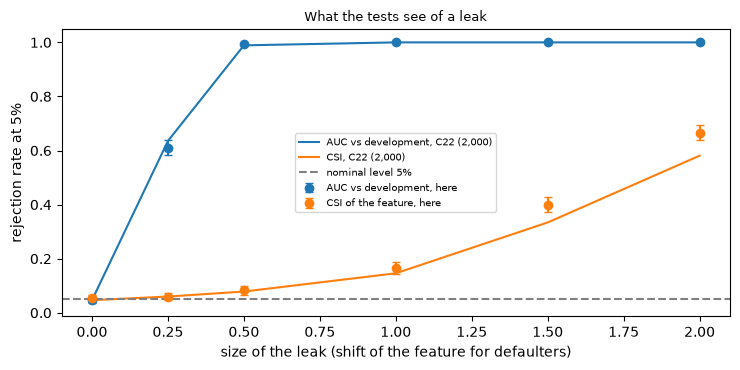

committed specimen, leak 1, p (AUC, CSI): 4.56e-16 0.639


In [9]:
# The rates of this notebook against the rates committed in C22 (2000 repetitions), with the Monte Carlo error
sims = {s["key"]: s for s in c22["outputs"]["simulations"]}
committed = {kind: [sims[f"{kind}@l{x:g}"]["rates"]["p<0.05"]["rate"] for x in leaks] for kind in
             ("disc.auc_vs_initial", "stability.csi")}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
panels = [
    (0, "disc.auc_vs_initial", "AUC vs development, here", "AUC vs development, C22 (2,000)", "tab:blue"),
    (1, "stability.csi", "CSI of the feature, here", "CSI, C22 (2,000)", "tab:orange"),
]
for column, kind, label, line_label, color in panels:
    own = np.array([rates[x][column] for x in leaks])
    ax.errorbar(leaks, own, yerr=np.sqrt(own * (1 - own) / n_rep), fmt="o", color=color, capsize=3, label=label)
    ax.plot(leaks, committed[kind], color=color, linestyle="-", label=line_label)
ax.axhline(0.05, color="gray", linestyle="--", label="nominal level 5%")
ax.set_xlabel("size of the leak (shift of the feature for defaulters)")
ax.set_ylabel("rejection rate at 5%")
ax.set_title("What the tests see of a leak", fontsize=9)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
specimen = {t["test_id"]: t for t in c22["tests"]}
p_auc = float(f"{specimen['disc.auc_vs_initial']['p_value']:.3g}")
print("committed specimen, leak 1, p (AUC, CSI):", p_auc, round(specimen["stability.csi"]["p_value"], 3))

The figure supports the reading above. At 0.25 the AUC test rejects in 0.61 of the repetitions and the simulation matches the committed 0.635 within its error, and at leak 1 both are 1.0; the CSI points of the notebook sit above the committed curve at the large leaks (0.4 against 0.334 at 1.5, about two Monte Carlo standard errors of 300 repetitions); the notebook does not explain the gap beyond its seeds and its 300 repetitions against the 2,000 of C22, and the reading is the same. The committed specimen of C22, a single draw at leak 1, gives p of 4.56e-16 for the AUC test and 0.639 for the CSI (green), a reminder of how little one sample of the feature says. The slow rise of the CSI means a validator who watches only the stability of inputs would see a leak late, and a model builder who relies on that has no protection.

### The exact inflation

With the claim measured, the cell below shows what it is made of: the development AUC the leak produces, against the AUC the genuine score would give on new cards.

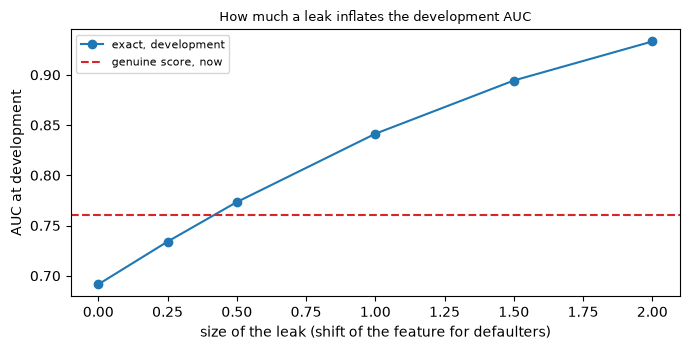

exact development AUC at leak 1, genuine AUC now: 0.8413 0.7602
exact inflation of the development AUC by a leak of 1: 0.1499


In [10]:
# The exact development AUC the generator knows for each leak size, against the AUC of the genuine score now
exact = [BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=x).truth() for x in leaks]
development = [t["auc_development"] for t in exact]
genuine = exact[0]["auc_genuine_current"]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(leaks, development, marker="o", label="exact, development")
ax.axhline(genuine, color="tab:red", linestyle="--", label="genuine score, now")
ax.set_xlabel("size of the leak (shift of the feature for defaulters)")
ax.set_ylabel("AUC at development")
ax.set_title("How much a leak inflates the development AUC", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("exact development AUC at leak 1, genuine AUC now:", round(development[3], 4), round(genuine, 4))
print("exact inflation of the development AUC by a leak of 1:", round(development[3] - development[0], 4))

## Results

**Answer:** A leak is seen by the validation tests as a drop of discrimination out of time, long before it is seen as a drift of the feature, and the protocol stops it before the fit rather than after. In the measurement of this notebook, with 300 seeded repetitions per leak size, the AUC against development rejects at 5% in 0.047 of the samples with no leak (its size), 0.61 with a leak of 0.25, 0.993 with 0.5 and 1.0 from 1 on, while the characteristic stability index of the leaked feature rejects in 0.053, 0.06, 0.083, 0.167, 0.4 and 0.667 at leaks of 0, 0.25, 0.5, 1, 1.5 and 2. The cause is exact: a leak of 1 inflates the development AUC from 0.7602, the genuine score, to 0.8413, an inflation of 0.1499. For the protocol, the three requirements CT-101 to CT-103 name their gates; C01 has 16,800 cards behind each of its 13 binned variables and its three calibration maps were fitted on the calibration slice; the four flags hold and the rows partition in the six C02 files; and in C03 the engine accepts the 6 vintages of the two latest cohorts and refuses a vintage whose 5-year mark (2026-09-30) postdates the file (2026-06-30), so FY2020 is the last testable year.

What the claim states is the enforcement of known rules, case by case, with a gate that fails and a statement of what each split cannot claim; it is not a new method, and this notebook does not run the gates (they need the pipeline libraries). The leak planted is synthetic and of one kind, a feature that carries the outcome in development; a leak by time, a value dated after the observation date, is covered by the gate CT-103 and by the engine's rule on vintages, not by this demonstration. The evaluation framework of Kozodoi et al. (2025) addresses a different problem, the sampling bias of accepted and rejected applicants.

## Summary

- The claim: the leakage-safe protocol is declared per case and enforced by gates. The rules are known (dossier 04); the product adds a named, failing test for each (CT-101 to CT-103) and a split declared and recorded for each case.
- On the committed artifacts, what the gates guarantee holds: counts from the training slice alone, calibration on its own slice, flags that refuse an out-of-time claim, and a target read only where it is observable, with the engine refusing the vintage that is not.
- The protocol states what each split cannot claim: C01 has no out-of-time validation, C02 makes no out-of-time claim, C03 is a federal programme.
- Measured by simulation and against the exact truth of the generator, a leak is seen by the tests as a drop of discrimination out of time and only late as a drift of the feature, which is why it has to be stopped before the fit.

**What to try next.** Change the separation of the generator in the Beyond section and see how the power of the AUC test against development moves; read `tests/test_leakage.py` and run it in the pipeline environment (`python -m pytest tests/test_leakage.py`); then continue with the other topics, which apply the same discipline to their own cases.

## References

- Mavin, A., Wilkinson, P., Harwood, A. and Novak, M. (2009), Easy Approach to Requirements Syntax (EARS), 17th IEEE International Requirements Engineering Conference. https://doi.org/10.1109/RE.2009.9
- Kozodoi, N., Lessmann, S., Alamgir, M., Moreira-Matias, L. and Papakonstantinou, K. (2025), Fighting sampling bias: a framework for training and evaluating credit scoring models, European Journal of Operational Research 324(2). https://doi.org/10.1016/j.ejor.2025.01.040
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.4.1 and Annex 3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Tomczak, S. (2016), Polish Companies Bankruptcy, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- This repository: dossiers 04, 06 and 07 of the research basis (`docs/design/SDD.md`), `docs/design/features/c01-retail-pd/requirements.md`, `tests/test_leakage.py`.